In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/mtsamples.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(4999, 6)
['Unnamed: 0', 'description', 'medical_specialty', 'sample_name', 'transcription', 'keywords']


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [3]:
df.info()
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Unnamed: 0         4999 non-null   int64 
 1   description        4999 non-null   object
 2   medical_specialty  4999 non-null   object
 3   sample_name        4999 non-null   object
 4   transcription      4966 non-null   object
 5   keywords           3931 non-null   object
dtypes: int64(1), object(5)
memory usage: 234.5+ KB
Unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
dtype: int64


In [5]:
for i in [0,100,2000]:
    row = df.iloc[i]
    print("SPECIALTY:", repr(row["medical_specialty"]))
    print("DESCRIPTION:", row["description"])
    print("TEXT:", str(row["transcription"])[:600])
    print("-"*80)

SPECIALTY: ' Allergy / Immunology'
DESCRIPTION:  A 23-year-old white female presents with complaint of allergies.
TEXT: SUBJECTIVE:,  This 23-year-old white female presents with complaint of allergies.  She used to have allergies when she lived in Seattle but she thinks they are worse here.  In the past, she has tried Claritin, and Zyrtec.  Both worked for short time but then seemed to lose effectiveness.  She has used Allegra also.  She used that last summer and she began using it again two weeks ago.  It does not appear to be working very well.  She has used over-the-counter sprays but no prescription nasal sprays.  She does have asthma but doest not require daily medication for this and does not think it is 
--------------------------------------------------------------------------------
SPECIALTY: ' Urology'
DESCRIPTION:  Right inguinal hernia.    Right direct inguinal hernia repair with PHS mesh system.  The Right groin and abdomen were prepped and draped in the standard sterile s

Number of classes: 40
medical_specialty
Surgery                          1103
Consult - History and Phy.        516
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  230
Neurology                         223
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Urology                           158
Discharge Summary                 108
ENT - Otolaryngology               98
Neurosurgery                       94
Hematology - Oncology              90
Ophthalmology                      83
Nephrology                         81
Emergency Room Reports             75
Pediatrics - Neonatal              70
Pain Management                    62
Psychiatry / Psychology            53
Office Notes                       51
Podiatry                           47
Dermatology                        29
Dentistry                          27
Cosmetic /

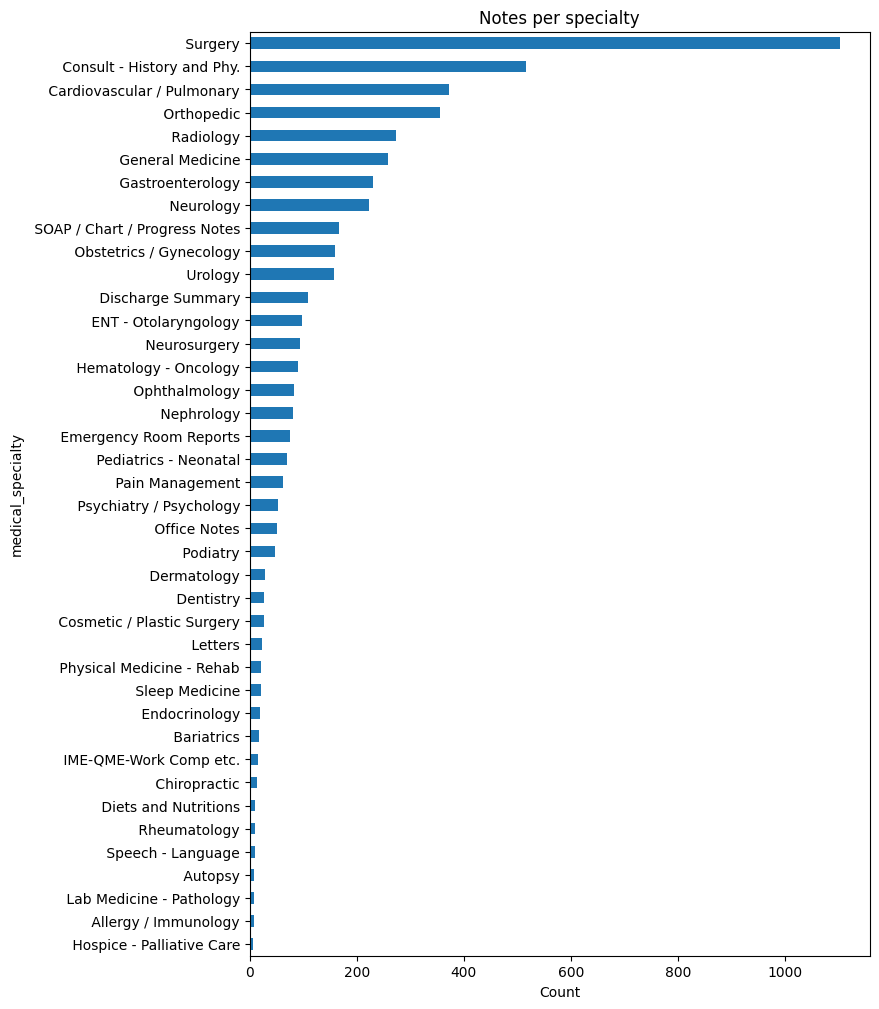

In [6]:
counts = df["medical_specialty"].value_counts()
print("Number of classes:", len(counts))
print(counts)

counts.plot(kind="barh", figsize=(8, 12))
plt.gca().invert_yaxis()
plt.title("Notes per specialty")
plt.xlabel("Count")
plt.show()

count    4999.000000
mean      462.376275
std       317.585206
min         0.000000
25%       239.000000
50%       397.000000
75%       614.000000
max      3029.000000
Name: n_words, dtype: float64


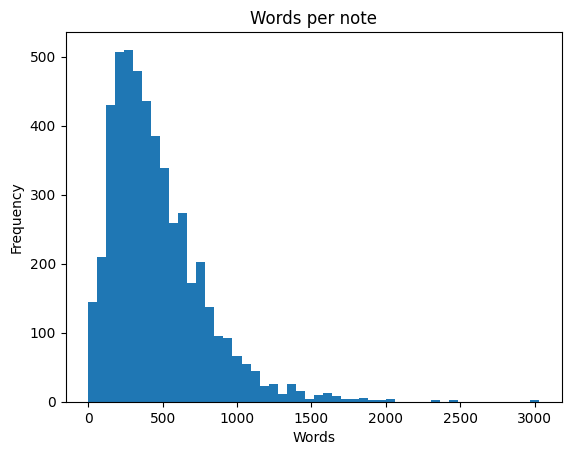

In [8]:
df["n_words"] = df["transcription"].fillna("").str.split().str.len()
print(df["n_words"].describe())

df["n_words"].plot(kind="hist", bins=50)
plt.title("Words per note")
plt.xlabel("Words")
plt.show()

In [9]:
print(counts.index.tolist())

[' Surgery', ' Consult - History and Phy.', ' Cardiovascular / Pulmonary', ' Orthopedic', ' Radiology', ' General Medicine', ' Gastroenterology', ' Neurology', ' SOAP / Chart / Progress Notes', ' Obstetrics / Gynecology', ' Urology', ' Discharge Summary', ' ENT - Otolaryngology', ' Neurosurgery', ' Hematology - Oncology', ' Ophthalmology', ' Nephrology', ' Emergency Room Reports', ' Pediatrics - Neonatal', ' Pain Management', ' Psychiatry / Psychology', ' Office Notes', ' Podiatry', ' Dermatology', ' Dentistry', ' Cosmetic / Plastic Surgery', ' Letters', ' Physical Medicine - Rehab', ' Sleep Medicine', ' Endocrinology', ' Bariatrics', ' IME-QME-Work Comp etc.', ' Chiropractic', ' Diets and Nutritions', ' Rheumatology', ' Speech - Language', ' Autopsy', ' Lab Medicine - Pathology', ' Allergy / Immunology', ' Hospice - Palliative Care']


In [10]:
print((df["n_words"] > 400).mean())

0.4928985797159432


## Findings

- Rows: 4,999, columns: 6 (`Unnamed: 0` is a leftover saved index, not data)
- Notes with missing transcription: 33 → drop them (they can't be classified)
- `keywords` missing in 1,068 rows → not used as model input
- Number of classes: 40
- Largest class: Surgery (1,103 notes); smallest: Hospice - Palliative Care (6 notes) → imbalance ratio about 184:1
- 18 of 40 classes have fewer than 50 notes (long-tail distribution)
- Words per note: median 397, mean 462, max 3,029
- Notes longer than 400 words: 49% → about half exceed DistilBERT's 512-token limit (medical words split into several subword tokens)

### Label problems
- Every label has a leading space (e.g. `' Surgery'`), found with `repr()` → needs `.str.strip()`
- Overlapping labels: example 100 is a hernia repair (general surgery) labelled Urology → check duplicate notes across classes on Day 2

### Suspicious classes (document types, not specialties)
- Consult - History and Phy. (516), SOAP / Chart / Progress Notes (166), Discharge Summary (108),
  Emergency Room Reports (75), Office Notes (51), Letters (23), IME-QME-Work Comp etc. (16), Autopsy (8)
- About 963 notes (19%) are labelled by note type instead of specialty → remove these classes so the task has one consistent definition

### Plan for Day 2
- Drop empty notes, strip label spaces, remove document-type classes
- Check for duplicate transcriptions
- Set a minimum class size, then do a stratified train/val/test split